
# Voice of Customer — SDAIA NLP Capstone

## Project Overview

This project develops an NLP application to analyze customer reviews, classify sentiment, and identify recurring customer complaints.

**Dataset:** Amazon Reviews Multi (English)

**Pipeline:**
1. Data preparation and sentiment labeling
2. Baseline: TF-IDF + Logistic Regression
3. Pretrained Transformer: DistilBERT
4. Improved model: Frozen Embeddings + Linear Head
5. Semantic embeddings and K-Means clustering
6. Quantitative evaluation and error analysis
7. Gradio application

**Course source:**
https://github.com/SDAIAAcademy/applied-nlp


## 1. Load, filter, and sample dataset
used
 **1–2 stars = negative**, **4–5 stars = positive**, and exclude 3-star reviews.

In [1]:
!pip -q install "datasets>=3.0" "transformers>=4.45,<5" "sentence-transformers>=3.0" "scikit-learn>=1.3" "gradio>=4.0" pandas matplotlib joblib accelerate

In [2]:
import numpy as np, pandas as pd, random, os, time
from datasets import load_dataset
from sklearn.model_selection import train_test_split
SEED=42
random.seed(SEED); np.random.seed(SEED)
# Officially separated English files; the train split is sampled before loading into memory.
BASE="https://huggingface.co/datasets/goosmanlei/amazon_reviews_multi/resolve/main/en"
URLS={name: f"{BASE}/{name}.jsonl.gz" for name in ["train","validation","test"]}

def load_sample(split, per_class):
    # streaming avoids fetching entire 200k training rows in memory
    ds=load_dataset("json", data_files={split:URLS[split]}, split=split, streaming=True)
    rows={0:[],1:[]}
    for r in ds:
        stars=int(r["stars"])
        if stars==3: continue
        label=int(stars>=4)
        txt=str(r.get("review_body") or "").strip()
        if len(txt)<12: continue
        if len(rows[label])<per_class:
            rows[label].append({"text":txt,"label":label,"stars":stars,"review_id":r.get("review_id","")})
        if all(len(rows[k])>=per_class for k in (0,1)): break
    df=pd.DataFrame(rows[0]+rows[1]).sample(frac=1,random_state=SEED).reset_index(drop=True)
    if df.label.nunique()<2: raise ValueError(f"Not enough classes in {split}")
    return df

train=load_sample("train",600)  # 1200 training examples
valid=load_sample("validation",75) # 150 validation examples
test=load_sample("test",50) # 100 held-out test examples
# Avoid near-trivial leakage if text was duplicated across official splits.
seen=set(); cleaned=[]
for df in (train,valid,test):
    df=df.loc[~df.text.str.lower().str.strip().isin(seen)].drop_duplicates(subset="text").copy()
    seen.update(df.text.str.lower().str.strip())
    cleaned.append(df.reset_index(drop=True))
train,valid,test=cleaned
print("Split sizes:",len(train),len(valid),len(test))
print("Class counts in training:",train.label.value_counts().to_dict())
display(train.head(5))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Split sizes: 1200 150 100
Class counts in training: {1: 600, 0: 600}


,text,label,stars,review_id
0,I like the phones a lot. They were very easy t...,1,4,en_0696818
1,"I am disabled from terminal cancer, and pretty...",1,4,en_0419160
2,I bought a package of three. Two of them have ...,0,1,en_0928501
3,Toy was annihilated within 10 minutes by my he...,0,1,en_0757118
4,"I like the looks of the clock; however, it is ...",0,1,en_0625024


## 2. Train a real baseline
This model **learns** from labeled examples. I choosed TF-IDF + Logistic Regression (Day 1 decision-model pattern). and used validation for development and only report the test split at the end.

In [3]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import joblib
baseline=Pipeline([
    ("tfidf",TfidfVectorizer(ngram_range=(1,2),max_features=15000,sublinear_tf=True)),
    ("classifier",LogisticRegression(max_iter=1200,random_state=SEED))
])
baseline.fit(train.text,train.label)
val_pred=baseline.predict(valid.text)
print("Validation macro F1:",round(f1_score(valid.label,val_pred,average="macro"),3))
joblib.dump(baseline,"voc_baseline.joblib")

Validation macro F1: 0.84


['voc_baseline.joblib']


## 3. Local Pretrained Transformer

I used a pretrained DistilBERT sentiment classifier from Hugging Face to compare Transformer-based predictions with the TF-IDF + Logistic Regression baseline.

The selected model was previously fine-tuned on the SST-2 sentiment dataset. I use it directly without additional fine-tuning on our Amazon reviews.
and then I evaluate its performance using Macro F1-score and compare it with our other models on the same held-out test set.


In [4]:
import torch
from transformers import pipeline
MODEL_NAME="distilbert/distilbert-base-uncased-finetuned-sst-2-english"
device=0 if torch.cuda.is_available() else -1
sentiment_pipe=pipeline("text-classification",model=MODEL_NAME,device=device)
print("Device:","GPU" if device==0 else "CPU")

def transformer_predict(texts, batch_size=16):
    outputs=sentiment_pipe(list(texts),truncation=True,max_length=256,batch_size=batch_size)
    return np.array([int(x["label"].upper()=="POSITIVE") for x in outputs])

# Validation
transformer_val=transformer_predict(valid.text.tolist())
print("Transformer validation Macro F1:",round(f1_score(valid.label,transformer_val,average="macro"),3))

Device set to use cpu


Device: CPU
Transformer validation Macro F1: 0.784




## 4. Quantitative Evaluation on a Held-Out Test Set

I evaluated the NLP models using the same held-out test set of 100 customer reviews to compare their classification performance fairly.

The initial comparison includes TF-IDF + Logistic Regression and a pretrained DistilBERT sentiment classifier. The Frozen Embeddings + Linear Head model is evaluated in a later section using the same test examples.

Then calculated accuracy, Macro F1-score, precision, recall, and prediction time. We also identify model disagreements with the reference labels and generate files for manual error analysis.

Additionally, selected 30 test reviews for manual label verification to identify ambiguous examples and possible inconsistencies between star ratings and written sentiment.

The automatically suggested error categories are preliminary and require human verification.


In [5]:
from IPython.display import display
truth=test.label.to_numpy()
t0=time.perf_counter(); baseline_pred=baseline.predict(test.text); base_seconds=time.perf_counter()-t0
t0=time.perf_counter(); transformer_pred=transformer_predict(test.text.tolist()); tf_seconds=time.perf_counter()-t0
scores=[]
for name,pred,secs in [("TF-IDF Logistic Regression",baseline_pred,base_seconds),("Pretrained Transformer",transformer_pred,tf_seconds)]:
    scores.append({"model":name,"accuracy":round(accuracy_score(truth,pred),3),"macro_f1":round(f1_score(truth,pred,average="macro"),3),"seconds":round(secs,2)})
score_df=pd.DataFrame(scores)
display(score_df)
print("Transformer classification report:",classification_report(truth,transformer_pred,target_names=["Negative","Positive"],zero_division=0))
result=test.copy();result["baseline_pred"]=baseline_pred;result["transformer_pred"]=transformer_pred
result["baseline_correct"]=result.label==result.baseline_pred
result["transformer_correct"]=result.label==result.transformer_pred
# Categories are analyst-assigned heuristics; manually review and refine these for submission.
errors=result.loc[~result.transformer_correct].copy()
def suggest_error_type(row):
    t=row.text.lower()
    if any(s in t for s in ["but ","however","although"]): return "Mixed/contradictory sentiment"
    if any(s in t for s in ["not ","never","n't"]): return "Negation/context"
    if len(t)<60: return "Very short/ambiguous"
    return "Context/product-specific or label disagreement"
errors["error_category_suggestion"]=errors.apply(suggest_error_type,axis=1)
print("Number of Transformer mistakes:",len(errors),"— instructor asks to discuss >=10 failures if possible.")
display(errors[["text","label","transformer_pred","error_category_suggestion"]].head(15))
score_df.to_csv("evaluation_scores.csv",index=False)
result.to_csv("test_predictions.csv",index=False)
errors.to_csv("errors_TO_REVIEW.csv",index=False)
# 30 examples to hand-check. Fill the human_label and notes columns yourselves; do not claim review before doing it.
handcheck=result.sample(n=min(30,len(result)),random_state=SEED)[["text","stars","label"]].copy()
handcheck["human_label_TO_FILL"]=""
handcheck["reviewer_notes_TO_FILL"]=""
handcheck.to_csv("30_test_reviews_TO_HAND_CHECK.csv",index=False)
print("Saved scores, predictions, suggested errors and 30-review hand-check template")

,model,accuracy,macro_f1,seconds
0,TF-IDF Logistic Regression,0.90,0.900,0.01
1,Pretrained Transformer,0.82,0.816,18.49


Transformer classification report:               precision    recall  f1-score   support

    Negative       0.75      0.96      0.84        50
    Positive       0.94      0.68      0.79        50

    accuracy                           0.82       100
   macro avg       0.85      0.82      0.82       100
weighted avg       0.85      0.82      0.82       100

Number of Transformer mistakes: 18 — instructor asks to discuss >=10 failures if possible.


,text,label,transformer_pred,error_category_suggestion
12,I have owned 4 pairs of these boots and I have...,1,0,Mixed/contradictory sentiment
16,Love the series. The only reason why I gave it...,1,0,Negation/context
17,"Just right for us, towels, first aid kit, tool...",1,0,Mixed/contradictory sentiment
29,They were very comfortable but my toes touched...,1,0,Mixed/contradictory sentiment
32,This pole is longer than most of other poles o...,1,0,Very short/ambiguous
34,It's kind of hard to review medicine since I'm...,1,0,Negation/context
37,Covers your lady bits well however its more of...,1,0,Mixed/contradictory sentiment
41,Added so much to the projects! Works well.,0,1,Very short/ambiguous
43,"Didn’t last long, but manufacturer replaced it.",1,0,Mixed/contradictory sentiment
46,Chair came fast. Already put together and read...,1,0,Context/product-specific or label disagreement


Saved scores, predictions, suggested errors and 30-review hand-check template



## 5. Semantic Embeddings, Clustering, and Improved Sentiment Classification

This section uses a pretrained Sentence Transformer (`all-MiniLM-L6-v2`) to generate semantic embeddings for customer reviews.

**Complaint Clustering:** K-Means groups 200 negative reviews into four clusters to identify recurring complaint patterns. The clusters are interpreted using representative customer feedback. The Silhouette Score of 0.038 indicates that some complaint themes overlap.

**Improved Sentiment Model:** Reused the frozen embeddings to train a Logistic Regression classifier (linear head) on labeled customer reviews. Model settings are selected using validation data.

**Model Evaluation:** The improved model achieves 92% accuracy and 0.920 Macro F1 on the held-out test set, compared with 0.900 Macro F1 for the TF-IDF baseline.

**Customer Insights:** The application displays human-interpreted complaint themes and representative reviews for each cluster.


In [6]:
from sentence_transformers import SentenceTransformer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
embedder=SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
negative_reviews=pd.concat([train,valid],ignore_index=True)
negative_reviews=negative_reviews[negative_reviews.label==0].copy()
negative_reviews=negative_reviews.sample(n=min(200,len(negative_reviews)),random_state=SEED).reset_index(drop=True)
vectors=embedder.encode(negative_reviews.text.tolist(),normalize_embeddings=True,show_progress_bar=True)
N_CLUSTERS=4
clusterer=KMeans(n_clusters=N_CLUSTERS,random_state=SEED,n_init=10)
negative_reviews["cluster"]=clusterer.fit_predict(vectors)
cluster_score=silhouette_score(vectors,negative_reviews.cluster,metric="euclidean")
print("Negative review silhouette score:",round(cluster_score,3))
for cluster_id in range(N_CLUSTERS):
    idx=np.flatnonzero(negative_reviews.cluster.values==cluster_id)
    cent=clusterer.cluster_centers_[cluster_id]
    top=idx[np.argsort(np.linalg.norm(vectors[idx]-cent,axis=1))[:3]]
    print(f"CLUSTER {cluster_id}: {len(idx)} reviews")
    for i in top: print(" -",negative_reviews.iloc[i].text[:220].replace("\n"," "))
negative_reviews.to_csv("negative_review_clusters.csv",index=False)

Batches:   0%|          | 0/7 [00:00<?, ?it/s]

Negative review silhouette score: 0.038
CLUSTER 0: 22 reviews
 - Complete waste of money and false advertising. On the pictures it seems like it would taste good but when you get the product it is clearly not right. Do not buy this for your kids or yourself.
 - This product caused severe burning of my skin. I have used other brands with no problems
 - I decided to try this for my GERD after reading all those great reviews. I took two gels on an empty stomach as directed about 30 minutes before breakfast. After a few hours I became nauseous; this was followed by terrib
CLUSTER 1: 66 reviews
 - I have not received this product even though it says it was delivered.
 - Didn’t receive my item said it got delivered , but I never recieved it .
 - Did not deliver as pictured item. Received a knock off.
CLUSTER 2: 54 reviews
 - Doesnt work well. It's harder to use the screen. It's not even the same as advertised. What a waste of money.
 - Never worked.... no help in getting it fixed or replaced

In [7]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
import numpy as np
import joblib

# Step 1: Convert reviews into frozen embeddings
print("Creating training embeddings...")

X_train_emb = embedder.encode(
    train["text"].tolist(),
    batch_size=64,
    normalize_embeddings=True,
    show_progress_bar=True
)

print("Creating validation embeddings...")

X_valid_emb = embedder.encode(
    valid["text"].tolist(),
    batch_size=64,
    normalize_embeddings=True,
    show_progress_bar=True
)

# Step 2: Train a linear classifier
# Try different settings using validation data ONLY

best_f1 = -1
best_C = None
frozen_classifier = None

for C in [0.1, 1, 10]:

    model = LogisticRegression(
        C=C,
        max_iter=1000,
        random_state=42
    )

    model.fit(X_train_emb, train["label"])

    predictions = model.predict(X_valid_emb)

    score = f1_score(
        valid["label"],
        predictions,
        average="macro"
    )

    print(f"C={C} | Validation Macro F1: {score:.3f}")

    if score > best_f1:
        best_f1 = score
        best_C = C
        frozen_classifier = model

print("\nBest C:", best_C)
print("Best validation Macro F1:", round(best_f1, 3))

# Save the trained classifier
joblib.dump(
    frozen_classifier,
    "voc_frozen_embedding_head.joblib"
)

print("New model saved successfully!")


Creating training embeddings...


Batches:   0%|          | 0/19 [00:00<?, ?it/s]

Creating validation embeddings...


Batches:   0%|          | 0/3 [00:00<?, ?it/s]

C=0.1 | Validation Macro F1: 0.812
C=1 | Validation Macro F1: 0.853
C=10 | Validation Macro F1: 0.800

Best C: 1
Best validation Macro F1: 0.853
New model saved successfully!


In [8]:

import time
from sklearn.metrics import classification_report

# Evaluate on the same 100 unseen reviews
start = time.perf_counter()

X_test_emb = embedder.encode(
    test["text"].tolist(),
    batch_size=64,
    normalize_embeddings=True,
    show_progress_bar=True
)

frozen_test_pred = frozen_classifier.predict(X_test_emb)

frozen_seconds = time.perf_counter() - start

frozen_accuracy = accuracy_score(
    test["label"], frozen_test_pred
)

frozen_f1 = f1_score(
    test["label"],
    frozen_test_pred,
    average="macro"
)

print("Frozen Embeddings + Linear Head")
print("Test Accuracy:", round(frozen_accuracy, 3))
print("Test Macro F1:", round(frozen_f1, 3))

print(classification_report(
    test["label"],
    frozen_test_pred,
    target_names=["Negative", "Positive"]
))

# Add the model to our evaluation table
new_row = pd.DataFrame([{
    "model": "Frozen Embeddings + Linear Head",
    "accuracy": round(frozen_accuracy, 3),
    "macro_f1": round(frozen_f1, 3),
    "seconds": round(frozen_seconds, 2)
}])

score_df = pd.concat([
    score_df[
        score_df["model"] != "Frozen Embeddings + Linear Head"
    ],
    new_row
], ignore_index=True)

display(score_df)

score_df.to_csv("evaluation_scores.csv", index=False)

# Save predictions for later error analysis
result["frozen_head_pred"] = frozen_test_pred
result.to_csv("test_predictions.csv", index=False)


Batches:   0%|          | 0/2 [00:00<?, ?it/s]

Frozen Embeddings + Linear Head
Test Accuracy: 0.92
Test Macro F1: 0.92
              precision    recall  f1-score   support

    Negative       0.92      0.92      0.92        50
    Positive       0.92      0.92      0.92        50

    accuracy                           0.92       100
   macro avg       0.92      0.92      0.92       100
weighted avg       0.92      0.92      0.92       100



,model,accuracy,macro_f1,seconds
0,TF-IDF Logistic Regression,0.90,0.900,0.01
1,Pretrained Transformer,0.82,0.816,18.49
2,Frozen Embeddings + Linear Head,0.92,0.920,6.03


In [9]:

# Human-interpreted themes from representative reviews
issue_themes = {
    0: "Mixed complaints about misleading product descriptions and adverse reactions.",
    1: "Customers report missing deliveries and incorrect orders.",
    2: "Customers describe products that do not work and problems getting replacements.",
    3: "Customers report poor materials, incorrect fit, and products breaking quickly."
}

def cluster_insights():
    summaries = []

    for cid in range(N_CLUSTERS):
        idx = np.flatnonzero(
            negative_reviews["cluster"].values == cid
        )

        center = clusterer.cluster_centers_[cid]
        distances = np.linalg.norm(
            vectors[idx] - center, axis=1
        )
        best = idx[np.argsort(distances)[:2]]

        examples = [
            negative_reviews.iloc[i]["text"][:220]
            .replace("\n", " ")
            for i in best
        ]

        section = (
            f"### Cluster {cid} — {len(idx)} reviews\n\n"
            f"**Observed theme:** {issue_themes[cid]}\n\n"
            "**Representative feedback:**\n"
            + "\n".join(f"- {review}" for review in examples)
        )

        summaries.append(section)

    summaries.append(
        "**Note:** Themes are provisional human "
        "interpretations, not LLM-generated summaries. "
        f"Silhouette Score: {cluster_score:.3f}"
    )

    return "\n\n".join(summaries)

print("Insight summaries ready!")


Insight summaries ready!




## 6. Evidence-Based Complaint Summaries and Model Evaluation

This section presents representative customer reviews and cluster sizes to provide evidence-based insights into recurring complaints.

The cluster summaries are extractive and human-interpreted rather than LLM-generated.

Also I evaluate improved Frozen Embeddings + Linear Head model using a classification report and confusion matrix.

The improved model correctly classified 92 out of 100 test reviews, achieving 92% accuracy and 0.920 Macro F1.


In [10]:
def cluster_insights_preview():
    chunks=[]
    for cid in range(N_CLUSTERS):
        idx=np.flatnonzero(negative_reviews.cluster.values==cid)
        center=clusterer.cluster_centers_[cid]
        best=idx[np.argsort(np.linalg.norm(vectors[idx]-center,axis=1))[:2]]
        quotes=[negative_reviews.iloc[i].text[:165].replace("\n"," ") for i in best]
        chunks.append(f"### Cluster {cid} — {len(idx)} complaints\n" + "\n".join(f"- {q}" for q in quotes))
    return "\n\n".join(chunks)
print(cluster_insights_preview()[:2500])

### Cluster 0 — 22 complaints
- Complete waste of money and false advertising. On the pictures it seems like it would taste good but when you get the product it is clearly not right. Do not buy thi
- This product caused severe burning of my skin. I have used other brands with no problems

### Cluster 1 — 66 complaints
- I have not received this product even though it says it was delivered.
- Didn’t receive my item said it got delivered , but I never recieved it .

### Cluster 2 — 54 complaints
- Doesnt work well. It's harder to use the screen. It's not even the same as advertised. What a waste of money.
- Never worked.... no help in getting it fixed or replaced

### Cluster 3 — 58 complaints
- Fits too small and the material breaks easily
- Cheap all peeled off in less than a month


              precision    recall  f1-score   support

    Negative       0.92      0.92      0.92        50
    Positive       0.92      0.92      0.92        50

    accuracy                           0.92       100
   macro avg       0.92      0.92      0.92       100
weighted avg       0.92      0.92      0.92       100



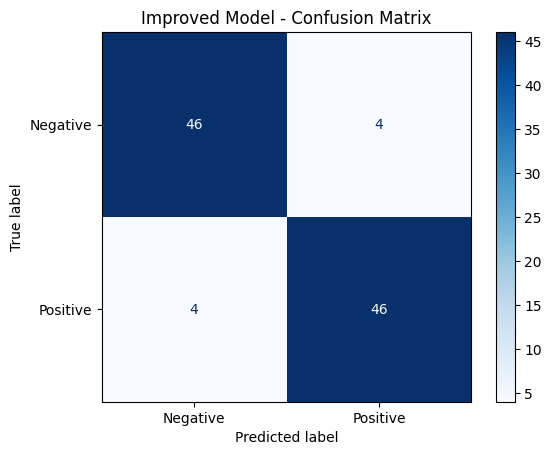

In [11]:

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report
)
import matplotlib.pyplot as plt

# Classification report for our improved model
print(classification_report(
    test["label"],
    frozen_test_pred,
    target_names=["Negative", "Positive"]
))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    test["label"],
    frozen_test_pred,
    display_labels=["Negative", "Positive"],
    cmap="Blues"
)

plt.title("Improved Model - Confusion Matrix")
plt.show()



## 7. Gradio Working Demo

I developed an interactive Gradio application to demonstrate our Voice of Customer NLP system.

**Single Review:** Users enter customer feedback and receive sentiment predictions from three models: TF-IDF + Logistic Regression, pretrained DistilBERT, and our improved Frozen Embeddings + Linear Head classifier. Negative reviews can also be assigned to exploratory complaint clusters.

**Recurring Complaints:** The application displays recurring complaint themes, cluster sizes, and representative customer reviews.

**Evaluation:** Users can view the quantitative comparison of all three models and the clustering Silhouette Score.

The application integrates pretrained Transformer models, a trained sentiment classifier, semantic embeddings, and K-Means clustering into an end-to-end NLP solution.


In [13]:

import gradio as gr


# Function to analyze a customer review
def analyze_review(review):

    if not review or not review.strip():
        return "Please enter a review.", "", "", ""

    # Model 1: TF-IDF + Logistic Regression (Baseline)
    a = int(baseline.predict([review])[0])

    # Model 2: Pretrained DistilBERT Transformer
    b = int(transformer_predict([review])[0])

    # Generate semantic embeddings
    embedding = embedder.encode(
        [review],
        normalize_embeddings=True
    )

    # Model 3: Frozen Embeddings + Linear Head
    c = int(frozen_classifier.predict(embedding)[0])

    # Convert numerical labels into sentiment names
    names = {
        0: "Negative",
        1: "Positive"
    }

    # Assign complaint clusters only to negative reviews
    # based on the improved model's prediction
    if c == 0:
        group = int(clusterer.predict(embedding)[0])

        issue_result = (
            f"Nearest learned issue cluster: {group} "
            "(exploratory, not a verified category)"
        )
    else:
        issue_result = (
            "Not applicable - review classified as positive."
        )

    return (
        names[a],
        names[b],
        names[c],
        issue_result
    )


# Build Gradio application
with gr.Blocks(title="Voice of Customer NLP Capstone") as demo:

    gr.Markdown(
        "# Voice of Customer — Customer Review Analyzer"
    )

    # TAB 1: Single Review
    with gr.Tab("Single Review"):

        incoming = gr.Textbox(
            label="Customer review",
            lines=4,
            value="The product arrived late and the packaging was broken."
        )

        run = gr.Button("Analyze")

        p1 = gr.Textbox(
            label="Baseline - TF-IDF + Logistic Regression"
        )

        p2 = gr.Textbox(
            label="Pretrained Transformer - DistilBERT"
        )

        p4 = gr.Textbox(
            label="Our Improved Model - Frozen Embeddings + Linear Head"
        )

        p3 = gr.Textbox(
            label="Issue Cluster"
        )

        run.click(
            fn=analyze_review,
            inputs=incoming,
            outputs=[p1, p2, p4, p3]
        )

    # TAB 2: Recurring Complaints
    with gr.Tab("Recurring Complaints"):

        gr.Markdown(
            "Clustering was fitted on sampled negative reviews. "
            "The following themes are human-interpreted and "
            "supported by representative customer feedback."
        )

        btn = gr.Button("Show Insights")

        out = gr.Markdown()

        btn.click(
            fn=cluster_insights,
            outputs=out
        )

    # TAB 3: Evaluation
    with gr.Tab("Evaluation"):

        gr.Dataframe(
            value=score_df,
            interactive=False,
            label="Held-out Test Results"
        )

        gr.Markdown(
            f"Negative-review clustering silhouette score: "
            f"**{cluster_score:.3f}**"
        )


# Launch the application
demo.launch(
    share=True,
    debug=True,
    show_error=True,
    inline=False
)


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://567ee2418964c419a9.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


/usr/local/lib/python3.13/dist-packages/gradio/routes.py:1368: StarletteDeprecationWarning: 'HTTP_422_UNPROCESSABLE_ENTITY' is deprecated. Use 'HTTP_422_UNPROCESSABLE_CONTENT' instead.
  return await queue_join_helper(body, request, username)
/usr/local/lib/python3.13/dist-packages/gradio/routes.py:1368: StarletteDeprecationWarning: 'HTTP_422_UNPROCESSABLE_ENTITY' is deprecated. Use 'HTTP_422_UNPROCESSABLE_CONTENT' instead.
  return await queue_join_helper(body, request, username)
/usr/local/lib/python3.13/dist-packages/gradio/routes.py:1368: StarletteDeprecationWarning: 'HTTP_422_UNPROCESSABLE_ENTITY' is deprecated. Use 'HTTP_422_UNPROCESSABLE_CONTENT' instead.
  return await queue_join_helper(body, request, username)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://567ee2418964c419a9.gradio.live
